## Homework 4: Plotting and Examining Subsets of Data
#### Will Stelter

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats


### Problem 0: Fake data


In [3]:
# create an axis that goes from 0 to 100pi in e^5 steps
t = np.linspace(0,np.pi*100,int(1e5))

# create a sinusoidal function of t offset up by 10
N = 10 + np.sin(t)

# create random background data whose mean and variance depend on the sinusoidal function N - time variability
bkgd = stats.norm.rvs(size=int(1e5))*np.sqrt(N)+N

### Problem 1: Array Slicing
#### a) make a scatter plot of the first 1000 data points
#### b) generalize the code so it can be applied to any X contiguous points, then produce an example 
#### c) plot every 100th point of the entire data set

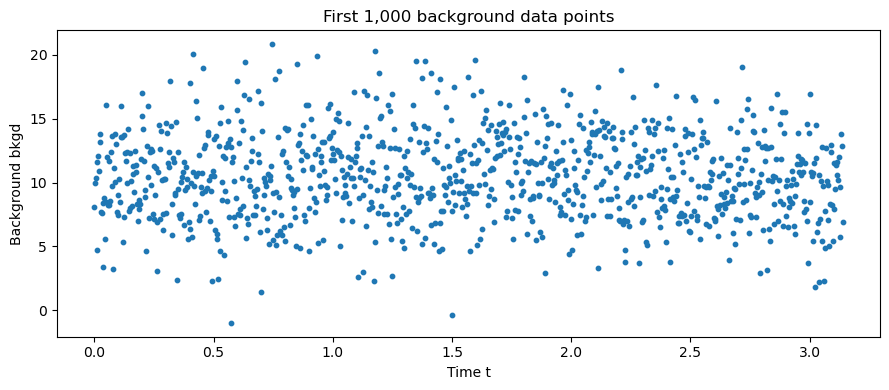

In [4]:
# 1a
# create an axis that goes from 0 to 100pi in e^5 steps
# t is now an array, beginning at 0 and ending at 100pi, with 100,000 individual steps
t = np.linspace(0,np.pi*100,int(1e5))

# create a sinusoidal function of t offset up by 10, the array N, with length 100,000
N = 10 + np.sin(t)

# create random background data whose mean and variance depend on the sinusoidal function N - time variability
# this is another array of length 100,000
bkgd = stats.norm.rvs(size=int(1e5))*np.sqrt(N)+N


# take slices of the arrays following form "slice" = "array"[start : stop : step length]
# no input for start -> python starts at 0th value, first value in the array
# no input for step length -> step sizes of 1
first_t = t[:1000]
first_bkgd = bkgd[:1000]

# plotting the 1st 1000 points
# 9 x 4 inch plot
plt.figure(figsize=(9, 4))

# scatter(horizontal coordinates, vertical coordinates, marker size)
plt.scatter(first_t, first_bkgd, s=10)

plt.xlabel("Time t")
plt.ylabel("Background bkgd")
plt.title("First 1,000 background data points")
plt.tight_layout()
plt.show()

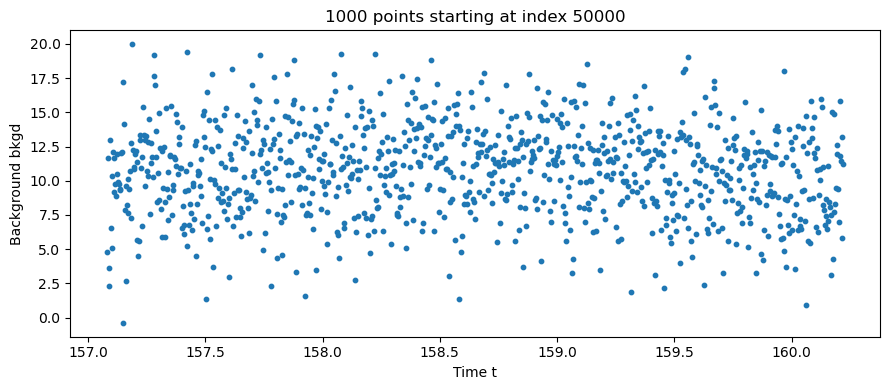

Number of selected points: 1000


In [5]:
# 1b - generalize code and produce example
# targets - 1000 more points beginning at 50,000th point

# create an axis that goes from 0 to 100pi in e^5 steps
# t is now an array, beginning at 0 and ending at 100pi, with 100,000 individual steps
t = np.linspace(0,np.pi*100,int(1e5))

# create a sinusoidal function of t offset up by 10, the array N, with length 100,000
N = 10 + np.sin(t)

# create random background data whose mean and variance depend on the sinusoidal function N - time variability
# this is another array of length 100,000
bkgd = stats.norm.rvs(size=int(1e5))*np.sqrt(N)+N

# set start point
start_point = 50000

# number of points
number_of_points = 1000

# set stop point equal to start point + number of points
stop_point = start_point + number_of_points

# slice arrays
target_t = t[start_point : stop_point]
target_bkgd = bkgd[start_point : stop_point]

# plot
# size, inches^2
plt.figure(figsize=(9,4))

# type of plot(x axis, y axis, marker size)
plt.scatter(target_t, target_bkgd, s=10)
plt.xlabel("Time t")
plt.ylabel("Background bkgd")
plt.title(f"{number_of_points} points starting at index {start_point}")
plt.tight_layout()
plt.show()

print("Number of selected points:", len(target_t))

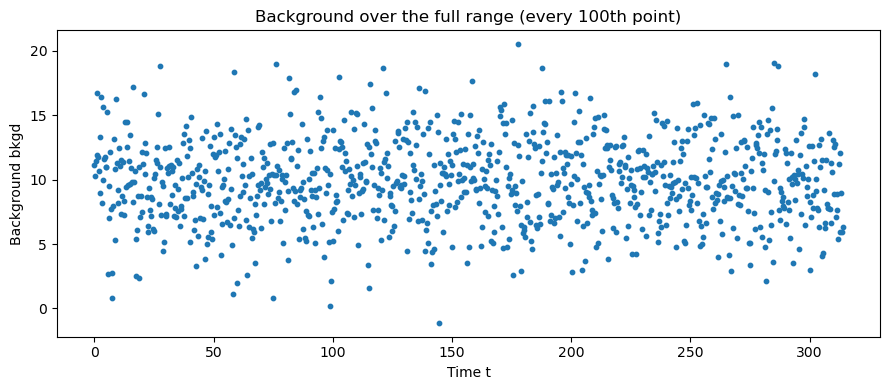

Original number of points: 100000
Number of sampled points: 1000


In [6]:
# 1c plot select points, every 100th
# sampling

# define data to sample
# array[start : stop : step size]
# no input for start and stop -> entire data set
sampled_t = t[::100]
sampled_bkgd = bkgd[::100]

#plot
# 9 x4 inches
plt.figure(figsize=(9, 4))
#scatter plot (x axis, y axis, marker size)
plt.scatter(sampled_t, sampled_bkgd, s=10)

plt.xlabel("Time t")
plt.ylabel("Background bkgd")
plt.title("Background over the full range (every 100th point)")
plt.tight_layout()
plt.show()

print("Original number of points:", len(t))
print("Number of sampled points:", len(sampled_t))

### Problem 2: Density
#### a) choose a method and make a 2D histogram (N = 100000)
#### b) interpret your plot

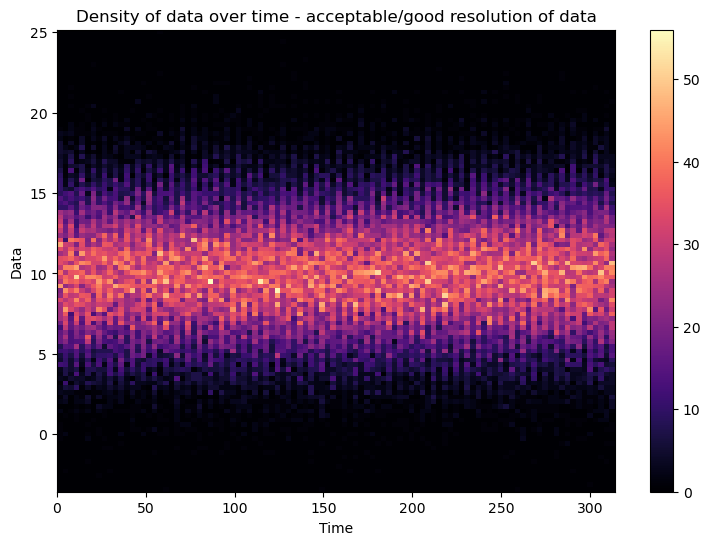

In [49]:
# create an axis that goes from 0 to 100pi in e^5 steps
# t is now an array, beginning at 0 and ending at 100pi, with 100,000 individual steps
t = np.linspace(0,np.pi*100,int(1e5))

# create a sinusoidal function of t offset up by 10, the array N, with length 100,000
N = 10 + np.sin(t)

# create random background data whose mean and variance depend on the sinusoidal function N - time variability
# each entry is = (a number randomly pulled from a Gaussian * the sqrt of function N) + the function N
# N has 100,000 distinct values, therefore this is another array of length 100,000
bkgd = stats.norm.rvs(size=int(1e5))*np.sqrt(N)+N

# plot commands
# 9x6 inches size
plt.figure(figsize=(9,6))
# 2D histogram (horizontal coord, vertical coord, bins=(x,y) or #^2 ?, range of inputs aka min and max values per axis, cmap aka color scheme)
# inputs (horizontal, vertical, ought to be arrays of the same length)
# range is left blank in order to include all input values
# semicolon appends extra notation stuff
plt.hist2d(t, bkgd, bins=100, cmap="magma");
plt.xlabel("Time")
plt.ylabel("Data")
plt.title("Density of data over time - acceptable/good resolution of data")
plt.colorbar()
plt.show()

## I'm not sure how to name these axes right. Having trouble wrapping my head around the way that the binning bundles the x and y inputs together ?

### 2b
#### The histogram above plots the density of points given by our function "bkgd" per time interval. Bkgd is a 100,000 item list where each item involves a random element and a time varying element. These items' values and corresponding time occurences are sorted into bins.
#### The lighter the color, the more counts were placed into the bin. 
#### We observe a higher-density band with unpredictable variation around the value 10. This makes sense, because bkgd is based on a sinusoidal cycle about the value 10, with a normal variance ever so slightly modifying each N(t).
#### It would be convenient for display purposes to restrict the range of the y values in the data, perhaps from 0<y<20. I have not done so above, but will do so in the additional plots below.

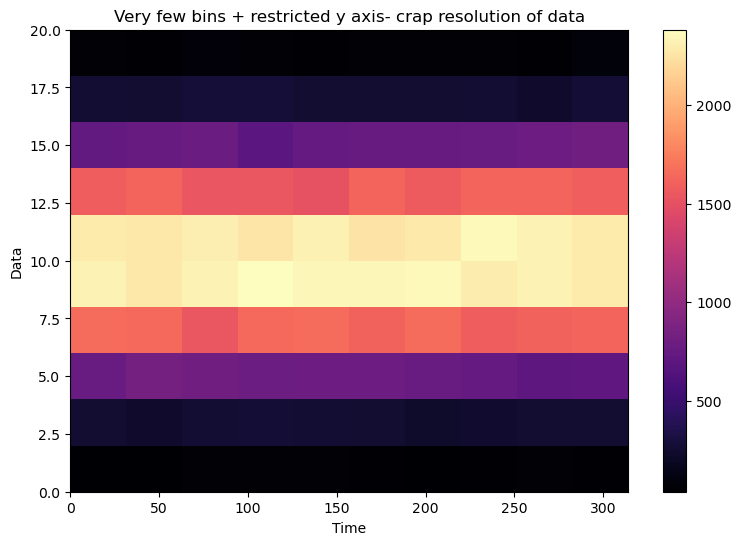

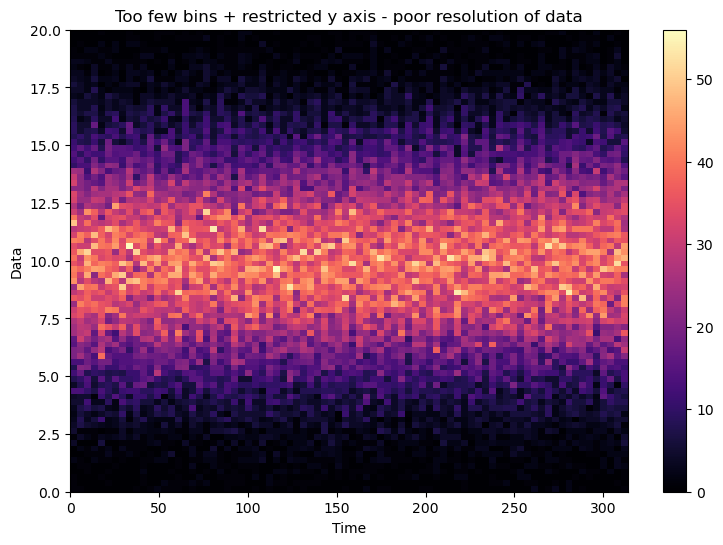

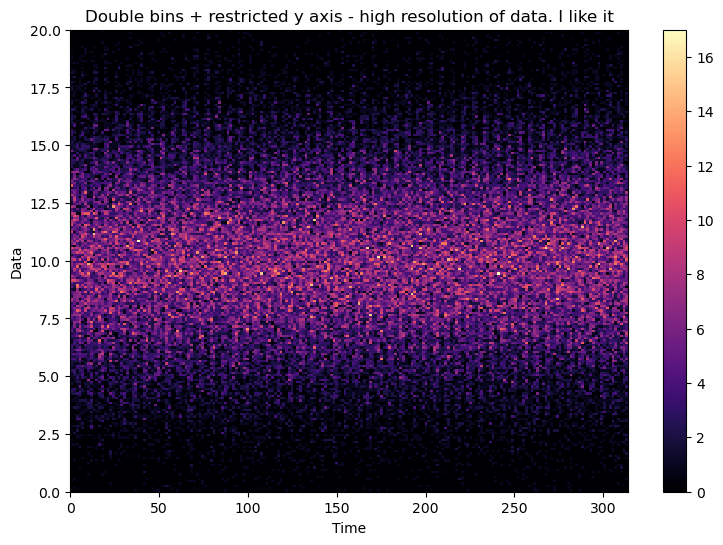

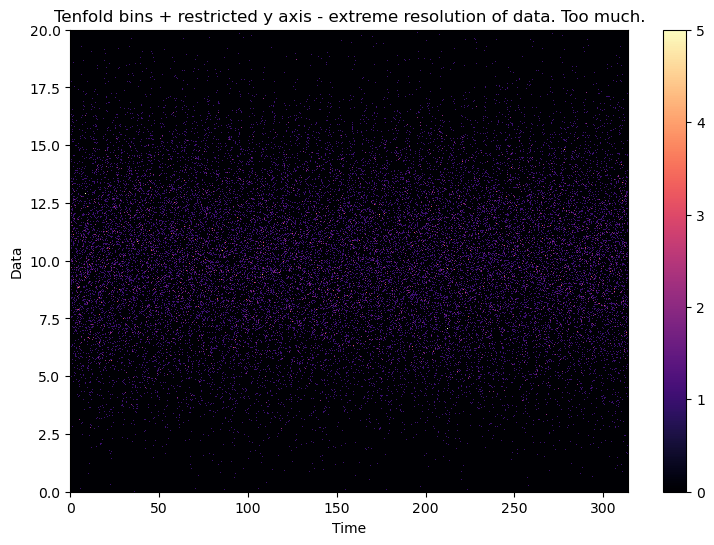

In [62]:
# additional plots, exploring bin values
# what EXACTLY is going on with bins=N ??

# 9x6 inches size
plt.figure(figsize=(9,6))
# 2D histogram (horizontal coord, vertical coord, bins=(x,y) or #^2 ?, range of inputs aka min and max values per axis, cmap aka color scheme)
# inputs (horizontal, vertical, ought to be arrays of the same length)
# range includes all horizontal coordinates and only those vertical coordinates between 0 and 20
# semicolon appends extra notation stuff
plt.hist2d(t, bkgd, bins=10, range=([np.min(t), np.max(t)],[0,20]), cmap="magma");
plt.xlabel("Time")
plt.ylabel("Data")
plt.title("Very few bins + restricted y axis- crap resolution of data")
plt.colorbar()
plt.show()


plt.figure(figsize=(9,6))
plt.hist2d(t, bkgd, bins=80, range=([np.min(t), np.max(t)],[0,20]), cmap="magma");
plt.xlabel("Time")
plt.ylabel("Data")
plt.title("Too few bins + restricted y axis - poor resolution of data")
plt.colorbar()
plt.show()

plt.figure(figsize=(9,6))
plt.hist2d(t, bkgd, bins=200, range=([np.min(t), np.max(t)],[0,20]), cmap="magma");
plt.xlabel("Time")
plt.ylabel("Data")
plt.title("Double bins + restricted y axis - high resolution of data. I like it")
plt.colorbar()
plt.show()

plt.figure(figsize=(9,6))
plt.hist2d(t, bkgd, bins=1000, range=([np.min(t), np.max(t)],[0,20]), cmap="magma");
plt.xlabel("Time")
plt.ylabel("Data")
plt.title("Tenfold bins + restricted y axis - extreme resolution of data. Too much.")
plt.colorbar()
plt.show()

## Problem 3: Folding
#### a) Fold into the data a new time variable with period 2pi. Scatter plot all (N=100000) this folded data
#### b) Make a 2D histogram of the folded data

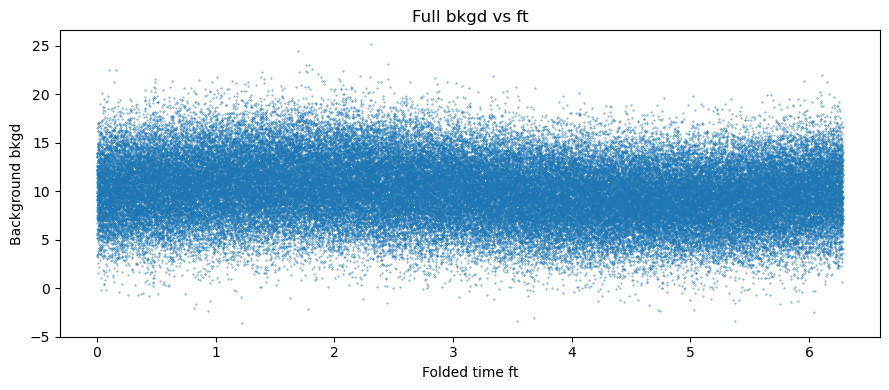

In [67]:
#3a
# ft for folded time
ft = t % (2 * np.pi)

# 9 x 4 inch plot
plt.figure(figsize=(9, 4))

# scatter(horizontal coordinates, vertical coordinates, marker size)
plt.scatter(ft, bkgd, s=.1)
plt.xlabel("Folded time ft")
plt.ylabel("Background bkgd")
plt.title("Full bkgd vs ft")
plt.tight_layout()
plt.show()

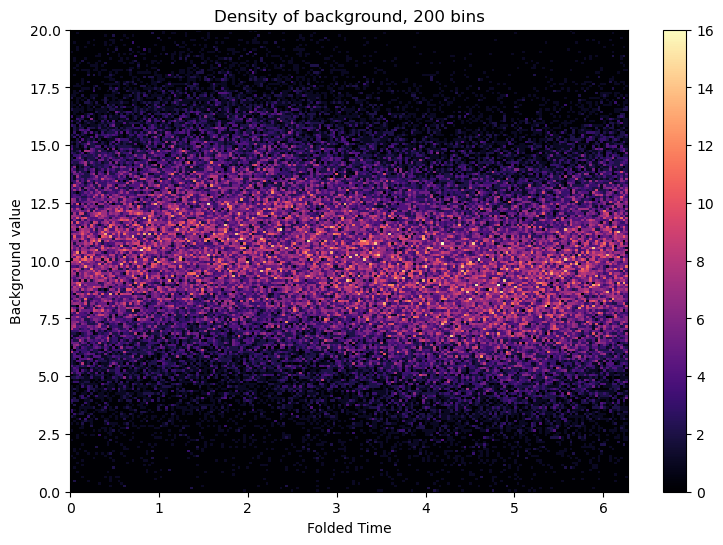

In [69]:
#3b
plt.figure(figsize=(9,6))
plt.hist2d(ft, bkgd, bins=200, range=([np.min(ft), np.max(ft)],[0,20]), cmap="magma");
plt.xlabel("Folded Time")
plt.ylabel("Background value")
plt.title("Density of background, 200 bins")
plt.colorbar()
plt.show()

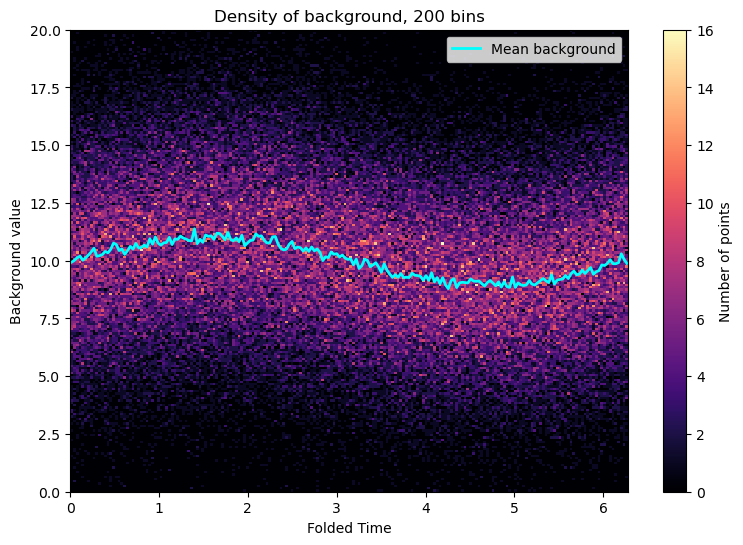

In [70]:
#3c
# trying an object-oriented plot approach for this 
# create the 2D histogram
fig, ax = plt.subplots(figsize=(9, 6))

# hist, xedges, yedges, image - objects returned when calling ax.hist2d()
# writing them out as such is multiple assignment/ unpacking
hist, xedges, yedges, image = ax.hist2d(ft, bkgd, bins=200, range=[[np.min(ft), np.max(ft)], [0, 20]], cmap="magma")

# calculate the mean background value in each folded-time bin
# stats.binned_statistic() returns 3 objects,
mean_bkgd, bin_edges, binnumber = stats.binned_statistic(ft, bkgd, statistic="mean", bins=xedges)

# find the center of each folded-time bin 
# ( Final minus initial ) / 2
ft_centers = (xedges[:-1] + xedges[1:]) / 2

# overlay the mean background values as a line
ax.plot(ft_centers, mean_bkgd, color="cyan", linewidth=2, label="Mean background")

# labels for plot
ax.set_xlabel("Folded Time")
ax.set_ylabel("Background value")
ax.set_title("Density of background, 200 bins")
ax.legend()

# color bar
fig.colorbar(image, ax=ax, label="Number of points")

plt.show()